# Evaluating and Improving the Tokyo Electricity Demand Model

**Starting point:** the Gradient Boosting model from the prediction project. It predicts hourly electricity demand in the Tokyo (TEPCO) area from weather and calendar features, with 2.6 % error on the 2026 test set. Its code is included unchanged as `original_model.py`.

**Plan**
1. Evaluate the original model with appropriate metrics.
2. Identify its weaknesses.
3. Improve it: better preprocessing and features, recent demand history, hyperparameter tuning, and different algorithms.
4. Compare the results and select the final model.

**Fair-comparison rules**
* Same data and the same split for every model: training on Apr 2022 – Dec 2025, testing on Jan – Oct 2026.
* The final model is chosen by **time-series cross-validation on the training years**, never by the test set. The test set is only used to report results.

All code is in `improve.py`. The next cell runs everything, which takes about 10 minutes because of the hyperparameter search.

In [1]:
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 20)
import improve as I

r = I.run(save=True)
comp = r["comparison"].astype(float)

## 1. Evaluate the original model

**Metrics used**

| Metric | Why it matters for electricity demand |
|---|---|
| MAE (GW) | Average size of the error, in the same unit as demand |
| RMSE (GW) | Punishes big misses more, which matters because large errors are costly for the grid |
| MAPE (%) | Error relative to demand; easy to compare across seasons |
| R² | Share of the variation in demand that the model explains |
| Max error (GW) | The worst single hour |
| Bias (GW) | Average of prediction minus actual; shows whether the model is systematically too high or too low |
| Peak-hours MAPE | Error in the top 5 % of demand hours, when the grid is most stressed |
| Special-days MAPE | Error on holiday periods and bridge days |
| Hours within 3 % | Share of hours where the prediction is close enough to be useful |
| Cross-validation MAPE | Average over 4 time-ordered folds in 2022–2025, showing how stable the model is |

In [2]:
metrics = ["cv_MAPE_pct", "MAE_GW", "RMSE_GW", "MAPE_pct", "R2", "max_error_GW", "bias_GW",
           "peak_hours_MAPE_pct", "special_days_MAPE_pct", "share_within_3pct"]
comp.loc[["Original model (Task 06)"], metrics].round(3).T

,Original model (Task 06)
cv_MAPE_pct,2.323
MAE_GW,0.814
RMSE_GW,1.088
MAPE_pct,2.589
R2,0.975
max_error_GW,6.627
bias_GW,0.344
peak_hours_MAPE_pct,2.796
special_days_MAPE_pct,3.234
share_within_3pct,66.637


## 2. Identify the weaknesses

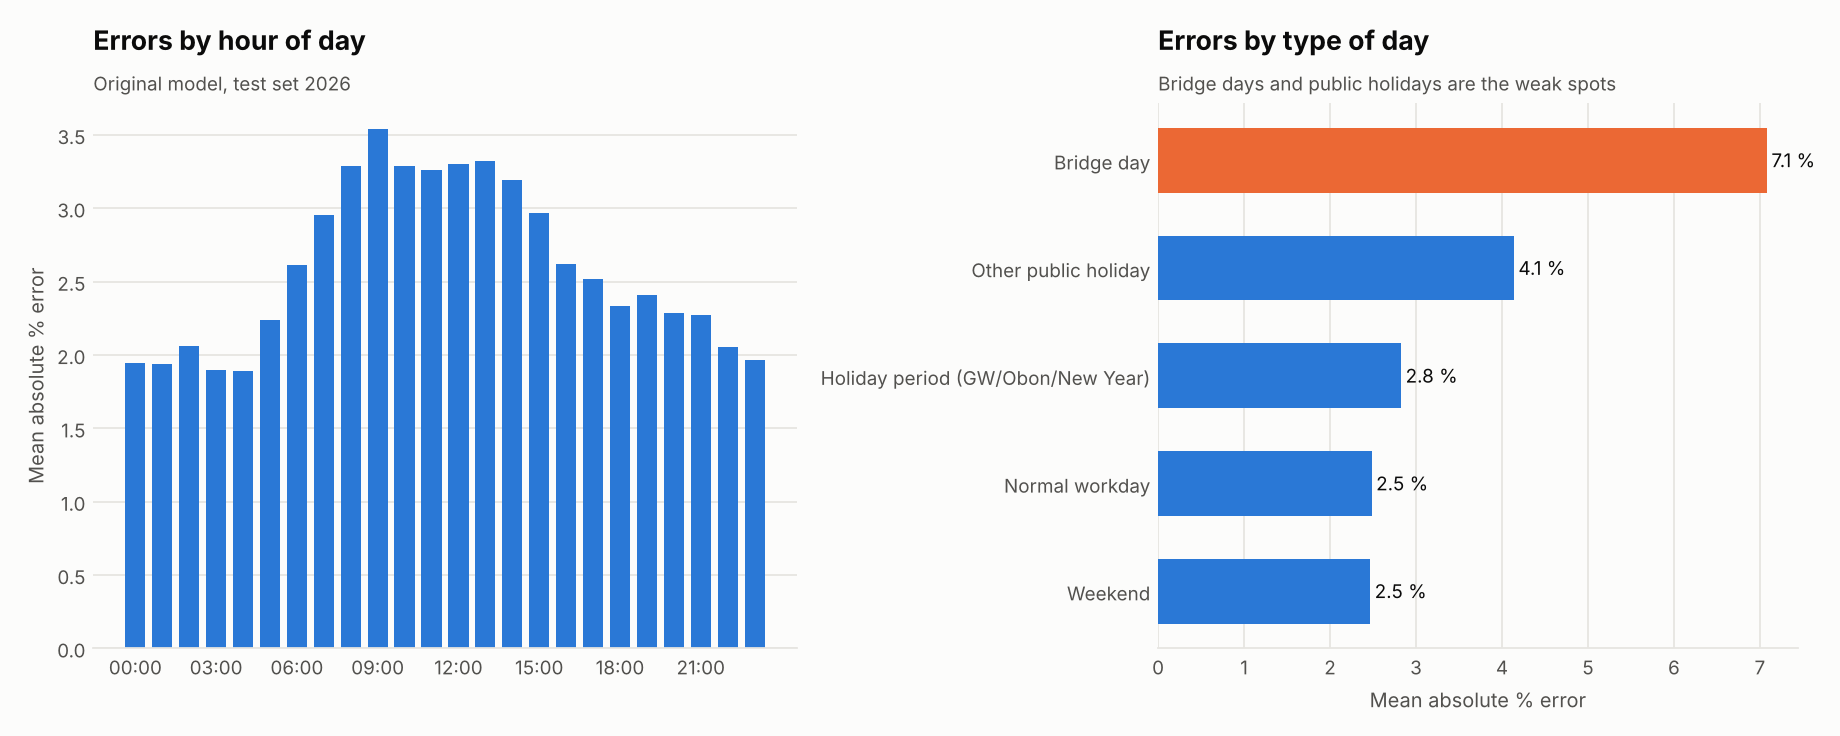

,MAPE_pct,hours
Bridge day,7.08,48
Holiday period (GW/Obon/New Year),2.83,456
Normal workday,2.49,4296
Other public holiday,4.14,216
Weekend,2.47,1824


In [3]:
display(Image("fig1_original_model_weaknesses.png", width=900))
pd.DataFrame({"MAPE_pct": r["weak"]["by_day_type"].round(2), "hours": r["weak"]["hours_by_day_type"]})

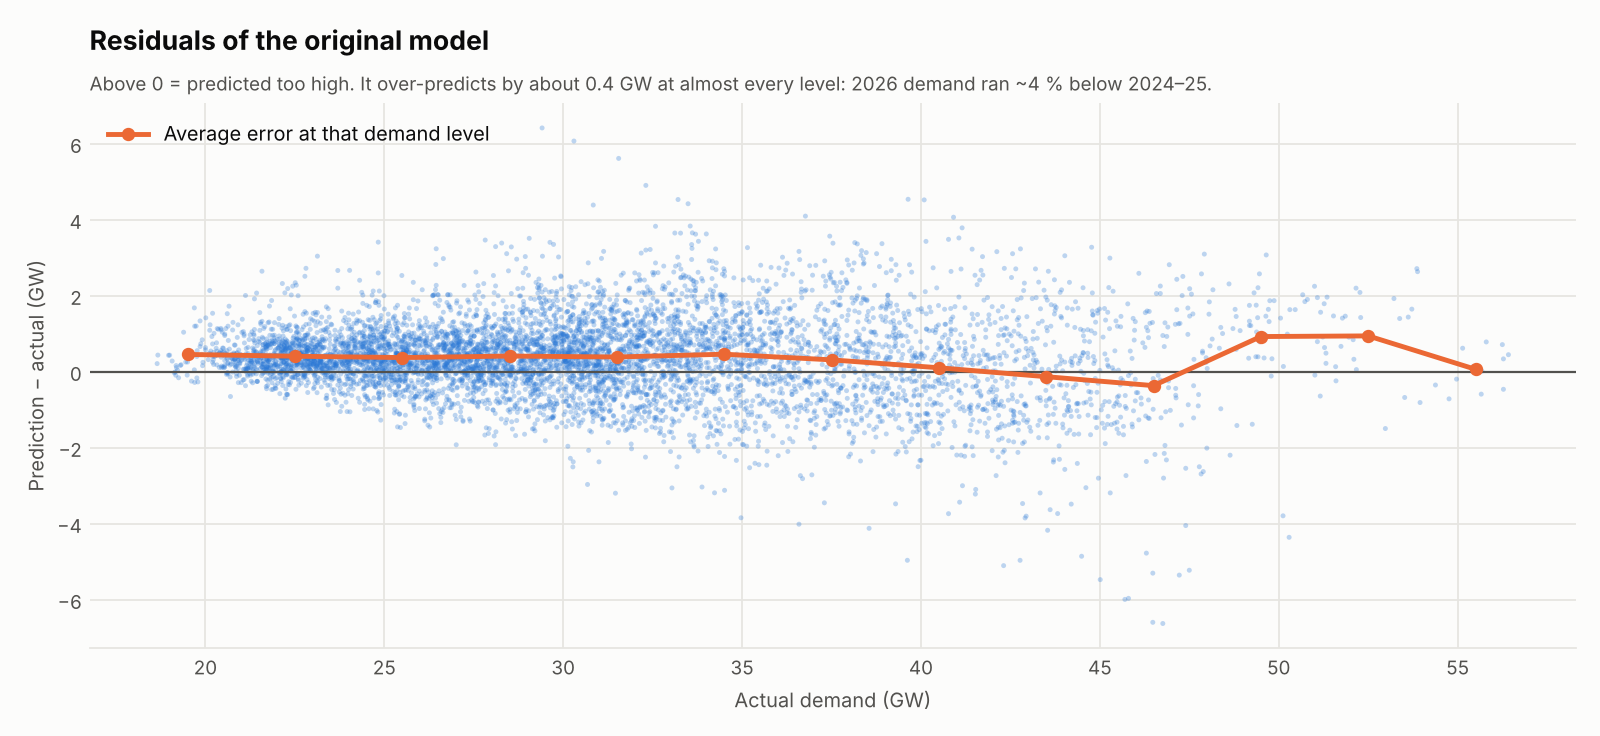

Average error (prediction - actual) by demand level, GW:
demand_gw
(18.648999999999997, 24.7]    0.42
(24.7, 28.286]                0.35
(28.286, 31.564]              0.41
(31.564, 36.652]              0.43
(36.652, 56.42]               0.11
dtype: float64

Average demand, Jan-Oct of each year (GW):
datetime
2022    31.49
2023    31.83
2024    32.27
2025    32.32
2026    30.94
Name: demand_gw, dtype: float64


In [4]:
display(Image("fig2_original_residuals.png", width=820))
print("Average error (prediction - actual) by demand level, GW:")
print(r["weak"]["by_demand_level"].round(2))
print("\nAverage demand, Jan-Oct of each year (GW):")
d = r["df"]; d = d[d.index.month <= 10]
print(d.groupby(d.index.year)["demand_gw"].mean().round(2))

In [5]:
print("Worst days for the original model (mean absolute % error):")
worst = r["weak"]["worst_days"].round(2).to_frame("MAPE_pct")
worst["weekday"] = worst.index.day_name()
worst

Worst days for the original model (mean absolute % error):


,MAPE_pct,weekday
datetime,,
2026-09-22,9.68,Tuesday
2026-02-08,9.17,Sunday
2026-08-12,8.57,Wednesday
2026-02-11,7.64,Wednesday
2026-06-07,6.89,Sunday
2026-06-06,6.45,Saturday
2026-05-25,6.26,Monday
2026-02-09,6.16,Monday


**Weaknesses found**
1. **Bridge days** (a workday between days off) have 7.1 % error, nearly 3 times the normal-workday error. Many people take that day off too, and the model can't know that.
2. **Public holidays** have 4.1 % error. The model doesn't know whether a holiday is a single day or part of a long block, such as Silver Week (19–23 Sep 2026), whose middle day had 9.7 % error.
3. **Systematic over-prediction (bias +0.34 GW).** Demand in 2026 was about 4 % lower than in 2024–25, but the model only learned from the past, so it predicts too high almost everywhere. This is called *drift*.
4. **Sudden cold snaps,** such as the snowy Sunday of 8 Feb 2026, are under-predicted.
5. **Daytime hours** (08:00–14:00) have the largest errors, peaking at 09:00 (3.5 %), when offices start up.

## 3. Improvements

| Step | What changed | Which weakness it targets |
|---|---|---|
| **1. Better preprocessing** | Calendar features: bridge day, previous/next day off, length of the days-off block, holiday period (Golden Week / Obon / New Year). Weather features: today's minimum temperature, temperature 3 h ago, 24 h heating- and cooling-degree averages | Weaknesses 1, 2, 4 |
| **2. Recent demand history** | Demand at the same hour 2 days ago and 1 week ago, plus the average and peak demand 2 days ago. All of these are **already known when forecasting the next day**, so there is no leakage | Weakness 3 (drift) |
| **3. Hyperparameter tuning** | `RandomizedSearchCV`, 20 settings × 4 time-series folds | General accuracy |
| **4. Different algorithms** | LightGBM, Random Forest and Extra Trees on the same features | Is a different model better? |

In [6]:
print("New features:", I.CALENDAR_V1 + I.WEATHER_V1 + I.LAGS_V2)
print("Best tuned settings:", r["best_params"])
r["test"][["demand_gw", "bridge_day", "off_run_length", "holiday_period", "demand_lag48h", "demand_lag168h"]].loc["2026-09-21":"2026-09-24"].iloc[::12]

New features: ['bridge_day', 'prev_day_off', 'next_day_off', 'off_run_length', 'holiday_period', 'temp_kanto_min_today_c', 'temp_kanto_3h_ago_c', 'heating_degrees_24h', 'cooling_degrees_24h', 'demand_lag48h', 'demand_lag168h', 'demand_d2_mean', 'demand_d2_max']
Best tuned settings: {'min_samples_leaf': 80, 'max_leaf_nodes': 48, 'max_iter': 1000, 'max_features': 0.5, 'learning_rate': 0.05, 'l2_regularization': 0.5}


,demand_gw,bridge_day,off_run_length,holiday_period,demand_lag48h,demand_lag168h
datetime,,,,,,
2026-09-21 00:00:00,23.08,0,5,0,23.96,23.99
2026-09-21 12:00:00,29.63,0,5,0,28.58,42.65
2026-09-22 00:00:00,23.70,0,5,0,23.49,27.72
2026-09-22 12:00:00,33.60,0,5,0,27.83,37.45
2026-09-23 00:00:00,24.83,0,5,0,23.08,26.25
2026-09-23 12:00:00,28.87,0,5,0,29.63,33.73
2026-09-24 00:00:00,22.98,0,0,0,23.70,24.69
2026-09-24 12:00:00,36.91,0,0,0,33.60,33.52


## 4. Compare the models

In [7]:
comp[["features"] + metrics].round(3)

,features,cv_MAPE_pct,MAE_GW,RMSE_GW,MAPE_pct,R2,max_error_GW,bias_GW,peak_hours_MAPE_pct,special_days_MAPE_pct,share_within_3pct
Original model (Task 06),17.0,2.323,0.814,1.088,2.589,0.975,6.627,0.344,2.796,3.234,66.637
Step 1: + calendar & weather features,26.0,2.266,0.790,1.052,2.516,0.976,6.422,0.299,2.613,2.926,66.974
Step 2: + recent demand history,30.0,2.114,0.694,1.000,2.176,0.979,8.154,0.075,2.753,3.397,75.980
Step 3: + tuned Gradient Boosting,30.0,1.952,0.642,0.911,2.017,0.982,6.317,0.088,2.443,3.103,78.056
Step 4: LightGBM,30.0,2.035,0.651,0.934,2.043,0.981,7.814,0.082,2.666,3.196,78.056
Step 4: Random Forest,30.0,2.528,0.797,1.151,2.529,0.972,8.391,0.142,3.130,4.456,70.234
Step 4: Extra Trees,30.0,2.228,0.722,1.047,2.279,0.977,8.673,0.137,2.891,3.781,73.874


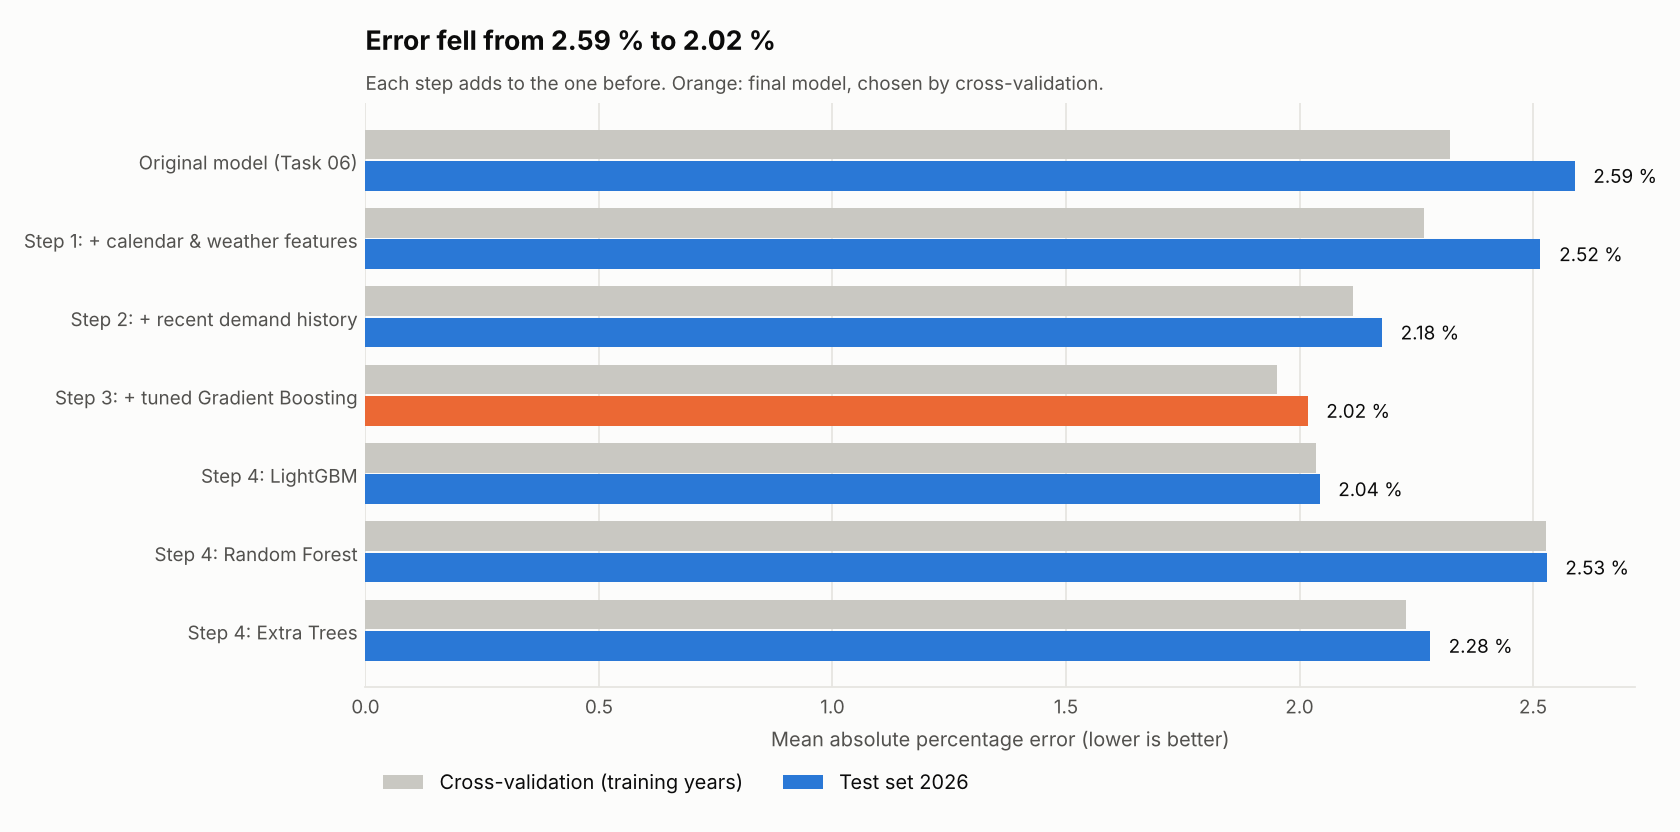

In [8]:
display(Image("fig3_improvement_steps.png", width=860))

## 5. Select the final model

In [9]:
print("Final model (lowest cross-validation MAPE):", r["final"])
before, after = comp.iloc[0], comp.loc[r["final"]]
summary = pd.DataFrame({"Original": before[metrics], "Final": after[metrics]})
summary["Change"] = summary["Final"] - summary["Original"]
summary.round(3)

Final model (lowest cross-validation MAPE): Step 3: + tuned Gradient Boosting


,Original,Final,Change
cv_MAPE_pct,2.323,1.952,-0.371
MAE_GW,0.814,0.642,-0.172
RMSE_GW,1.088,0.911,-0.177
MAPE_pct,2.589,2.017,-0.572
R2,0.975,0.982,0.008
max_error_GW,6.627,6.317,-0.310
bias_GW,0.344,0.088,-0.256
peak_hours_MAPE_pct,2.796,2.443,-0.353
special_days_MAPE_pct,3.234,3.103,-0.132
share_within_3pct,66.637,78.056,11.418


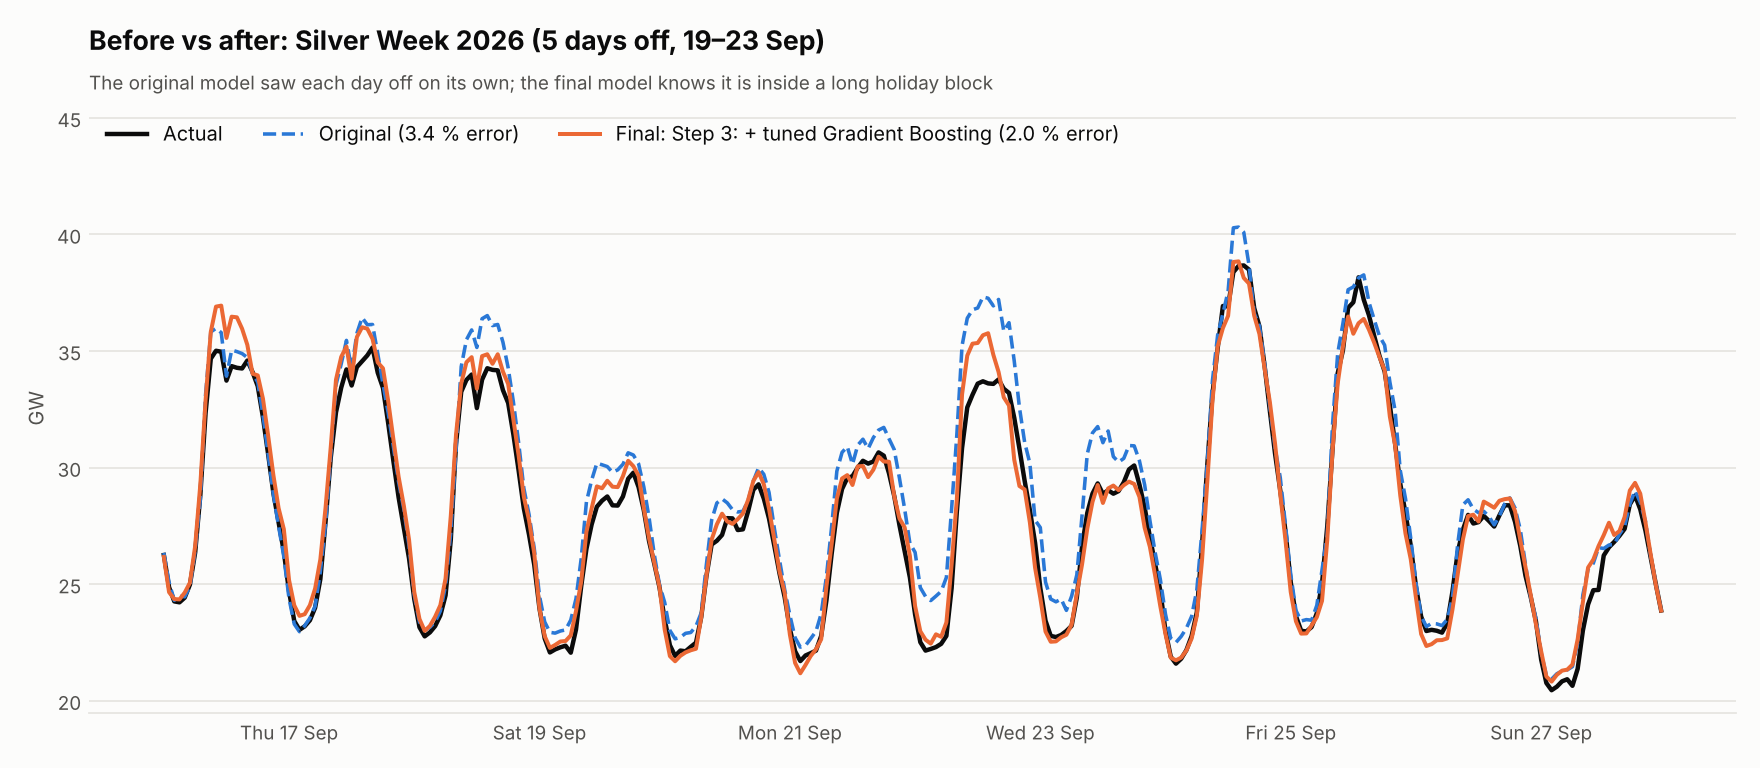

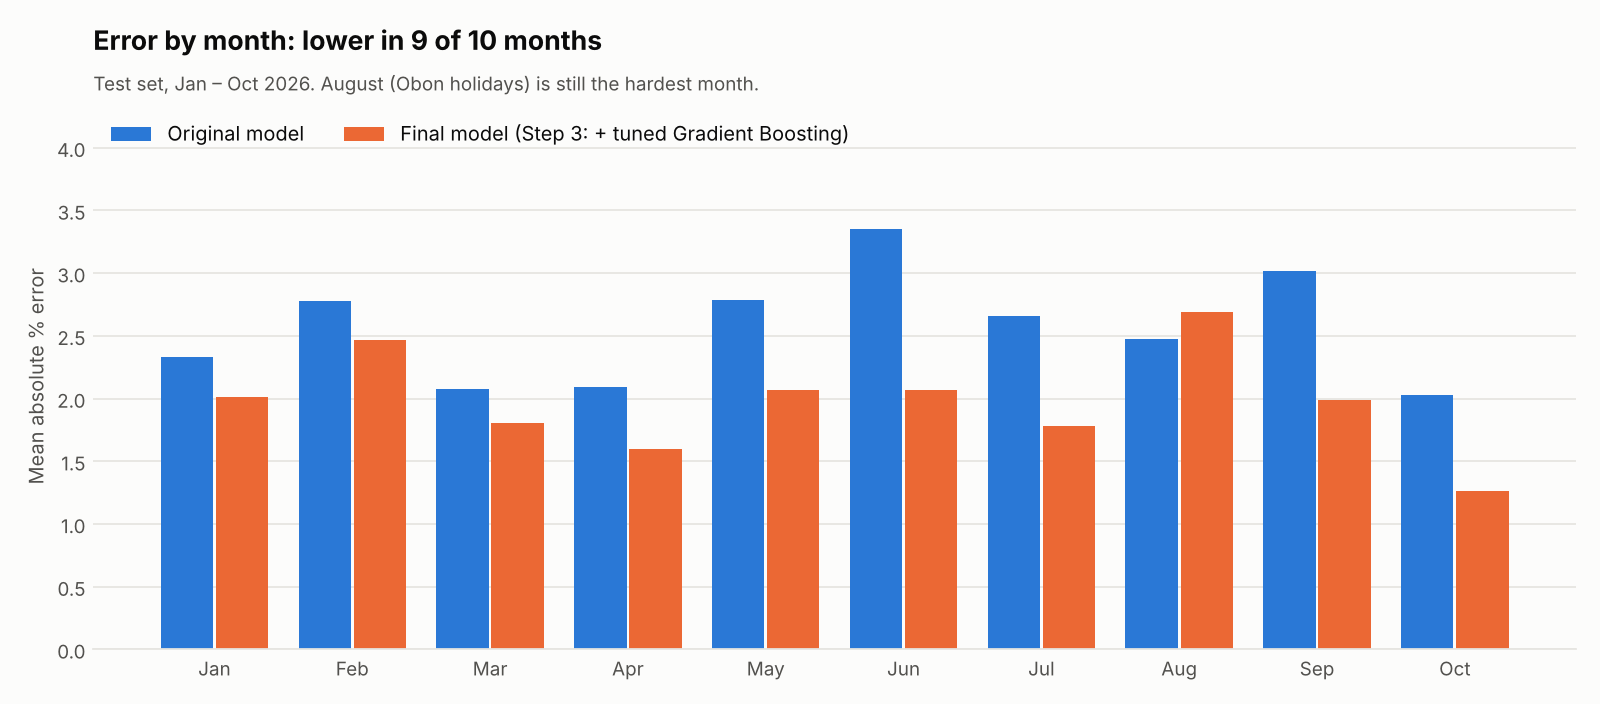

,original,final,hours
day_type,,,
Bridge day,7.08,5.29,48
Holiday period (GW/Obon/New Year),2.83,2.87,456
Normal workday,2.49,1.95,4296
Other public holiday,4.14,1.98,216
Weekend,2.47,1.88,1824


In [10]:
display(Image("fig4_silver_week_before_after.png", width=900))
display(Image("fig5_error_by_month_before_after.png", width=820))
pd.read_csv("error_by_day_type.csv", index_col=0)

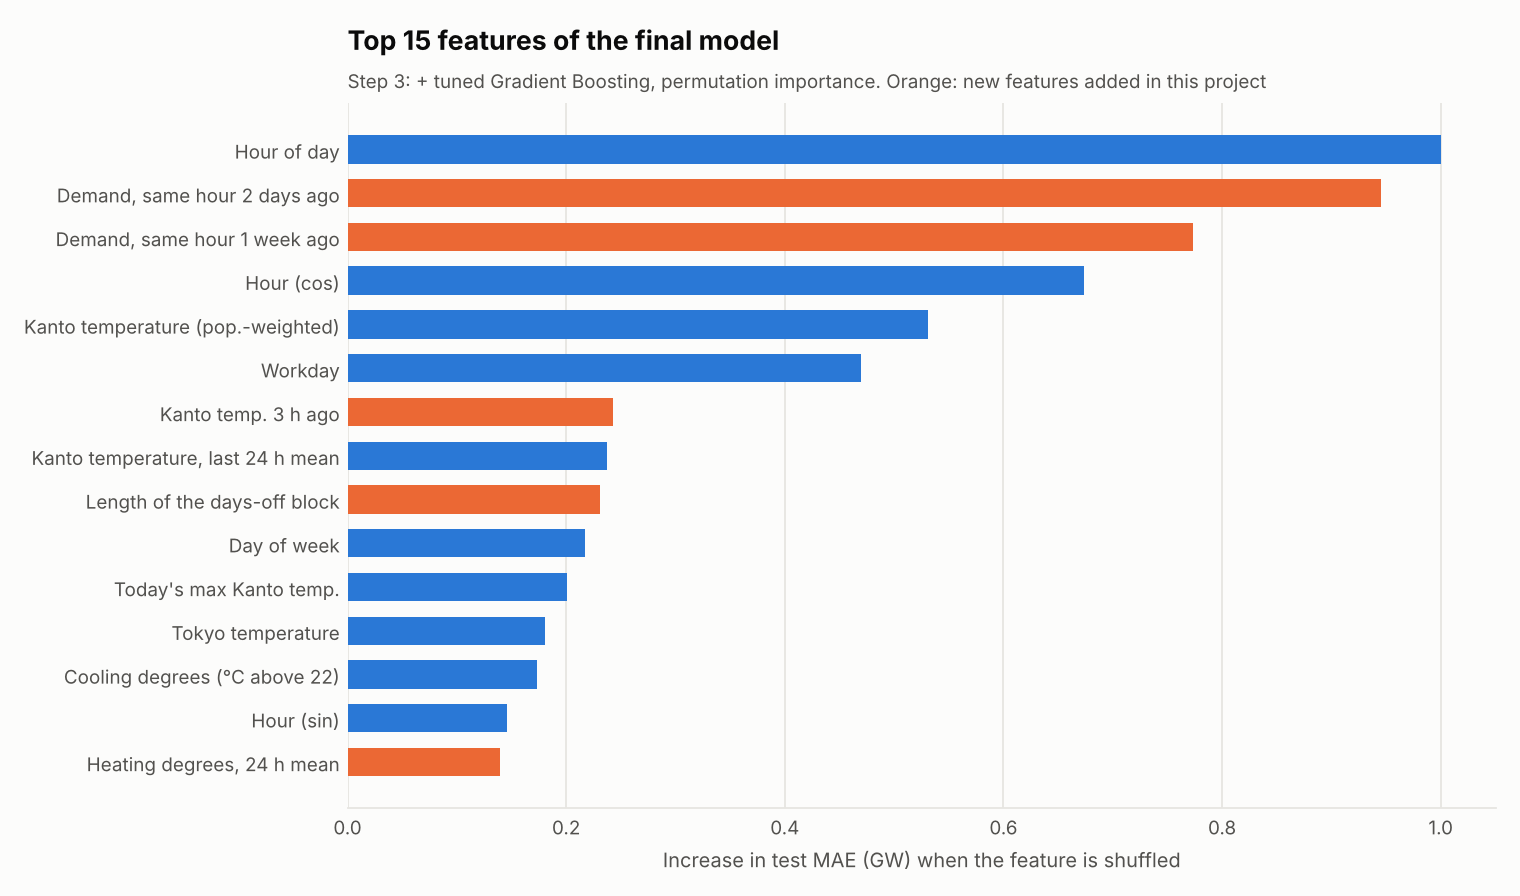

In [11]:
display(Image("fig6_final_feature_importance.png", width=800))

## Conclusion

**Final model: tuned Gradient Boosting** with 30 features (17 original + 13 new). It was chosen because it had the lowest cross-validation error (1.95 %) and was also the best on the test set.

| | Original | Final | Change |
|---|---:|---:|---:|
| MAPE | 2.59 % | **2.02 %** | −22 % |
| MAE | 0.81 GW | **0.64 GW** | −21 % |
| RMSE | 1.09 GW | **0.91 GW** | −16 % |
| R² | 0.975 | **0.982** | +0.007 |
| Bias | +0.34 GW | **+0.09 GW** | drift almost removed |
| Peak-hours MAPE | 2.80 % | **2.44 %** | better when it matters most |
| Hours within 3 % | 67 % | **78 %** | +11 points |

**What helped most:** the recent-demand features (step 2) gave the biggest gain, and they almost removed the 2026 drift. Tuning added a further step. LightGBM came very close (2.04 %); Random Forest and Extra Trees were weaker.

**What is still weak, honestly reported:** bridge days remain hard (7.1 % → 5.3 %). August got slightly *worse* (2.47 % → 2.69 %), because Obon is a different length every year and the 2026 holidays were spread out. Real weather *forecasts* (instead of observed weather) and an explicit "company holiday" calendar would be the next improvements.